# INFO 5006 Assignment 2 — Pratik Dhumal Individual Proof of Work

**Scope:** validate `job_link`, quantify cross-file linkage, build an integrated job–skill dataset, and document reproducible checks supporting RQ1/RQ2.

This notebook intentionally focuses on Pratik's assigned integration task rather than reproducing other members’ RQ1/RQ2 analyses.

In [1]:
!pip -q install kagglehub duckdb

from pathlib import Path
import kagglehub
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

path = Path(kagglehub.dataset_download("asaniczka/1-3m-linkedin-jobs-and-skills-2024"))
jobs_file = path / "linkedin_job_postings.csv"
skills_file = path / "job_skills.csv"

con = duckdb.connect()
con.execute(f"""
CREATE OR REPLACE VIEW jobs AS
SELECT * FROM read_csv_auto('{str(jobs_file).replace("'", "''")}', ALL_VARCHAR=TRUE, SAMPLE_SIZE=200000)
""")
con.execute(f"""
CREATE OR REPLACE VIEW skills AS
SELECT * FROM read_csv_auto('{str(skills_file).replace("'", "''")}', ALL_VARCHAR=TRUE, SAMPLE_SIZE=200000)
""")

100%|██████████| 1.88G/1.88G [01:31<00:00, 22.0MB/s]

Extracting files...


## 1. Source-level identifier checks

In [2]:
source_profile = con.execute("""
SELECT
  'Job postings' AS dataset, COUNT(*) AS rows, COUNT(DISTINCT job_link) AS unique_job_link,
  SUM(CASE WHEN job_link IS NULL OR TRIM(job_link)='' THEN 1 ELSE 0 END) AS missing_job_link
FROM jobs
UNION ALL
SELECT
  'Job skills', COUNT(*), COUNT(DISTINCT job_link),
  SUM(CASE WHEN job_link IS NULL OR TRIM(job_link)='' THEN 1 ELSE 0 END)
FROM skills
""").df()
display(source_profile)

assert source_profile.loc[0, 'rows'] == source_profile.loc[0, 'unique_job_link']
assert source_profile.loc[1, 'rows'] == source_profile.loc[1, 'unique_job_link']

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,dataset,rows,unique_job_link,missing_job_link
0,Job postings,1348454,1348454,0.0
1,Job skills,1296381,1296381,0.0


## 2. Cross-file linkage and join validation

In [3]:
linkage = con.execute("""
WITH counts AS (
  SELECT
    (SELECT COUNT(*) FROM jobs) AS postings_rows,
    (SELECT COUNT(*) FROM skills) AS skills_rows,
    (SELECT COUNT(*) FROM jobs j INNER JOIN skills s USING(job_link)) AS matched_jobs,
    (SELECT COUNT(*) FROM jobs j LEFT JOIN skills s USING(job_link) WHERE s.job_link IS NULL) AS postings_without_skills,
    (SELECT COUNT(*) FROM skills s LEFT JOIN jobs j USING(job_link) WHERE j.job_link IS NULL) AS skills_without_posting,
    (SELECT COUNT(*) FROM jobs j LEFT JOIN skills s USING(job_link)) AS left_join_rows,
    (SELECT SUM(CASE WHEN job_skills IS NULL OR TRIM(job_skills)='' THEN 1 ELSE 0 END) FROM skills) AS empty_skill_records
)
SELECT *,
       ROUND(100.0 * matched_jobs / postings_rows, 2) AS linkage_pct,
       left_join_rows - postings_rows AS duplicate_rows_created
FROM counts
""").df()
display(linkage.T)

assert int(linkage.loc[0,'duplicate_rows_created']) == 0
assert int(linkage.loc[0,'skills_without_posting']) == 0

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
postings_rows,1348454.00
skills_rows,1296381.00
matched_jobs,1296381.00
postings_without_skills,52073.00
skills_without_posting,0.00
left_join_rows,1348454.00
empty_skill_records,2007.00
linkage_pct,96.14
duplicate_rows_created,0.00


## 3. Build an integrated analysis-ready job–skill table

In [4]:
integrated = con.execute("""
SELECT
    j.job_link,
    j.job_title,
    j.company,
    j.job_location,
    s.job_skills
FROM jobs j
LEFT JOIN skills s USING(job_link)
""").df()

print('Integrated rows:', f'{len(integrated):,}')
print('Unique job_link:', f'{integrated.job_link.nunique():,}')
print('Rows with skill record:', f'{integrated.job_skills.notna().sum():,}')
display(integrated.head())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Integrated rows: 1,348,454
Unique job_link: 1,348,454
Rows with skill record: 1,294,374


,job_link,job_title,company,job_location,job_skills
0,https://www.linkedin.com/jobs/view/warehouse-a...,Warehouse Associate/ driver/ Inventory Control,Infrahire,"Groveport, OH","Warehouse Management, Inventory Control, Mater..."
1,https://www.linkedin.com/jobs/view/sales-super...,Sales Supervisor - Spencer's,Spencer's,"Jenks, OK","Sales, Customer Service, Merchandising, Invent..."
2,https://www.linkedin.com/jobs/view/lead-sales-...,LEAD SALES ASSOCIATE-FT,Dollar General,"Ballston Spa, NY","Customer service, Cash register operation, Mer..."
3,https://www.linkedin.com/jobs/view/registered-...,"Registered Nurse (Women, Infants, & Children) ...",Health eCareers,"Springfield, MO","Nursing, Registered Nurse license, Client care..."
4,https://www.linkedin.com/jobs/view/customer-se...,CUSTOMER SERVICE REPRESENTATIVE,Family Dollar,"Tyrone, PA","Customer service, POS system, Stocking shelves..."


## 4. Analyst and canonical Business Analyst coverage

In [5]:
analyst_summary = con.execute(r"""
WITH a AS (
    SELECT DISTINCT
        job_link,
        LOWER(TRIM(job_title)) AS title_clean
    FROM jobs
    WHERE regexp_matches(LOWER(job_title), '\banalysts?\b')
),
ba AS (
    SELECT *
    FROM a
    WHERE regexp_matches(title_clean, '\bbusiness\s+analysts?\b')
)
SELECT
    (SELECT COUNT(*) FROM a) AS analyst_jobs,
    (SELECT COUNT(*) FROM ba) AS canonical_ba_jobs,
    (
        SELECT COUNT(*)
        FROM ba b
        INNER JOIN skills s USING(job_link)
        WHERE s.job_skills IS NOT NULL
          AND TRIM(s.job_skills) <> ''
    ) AS ba_jobs_with_usable_skills
""").df()

analyst_summary["BA skill coverage %"] = (
    analyst_summary["ba_jobs_with_usable_skills"]
    / analyst_summary["canonical_ba_jobs"] * 100
).round(2)

display(analyst_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,analyst_jobs,canonical_ba_jobs,ba_jobs_with_usable_skills,BA skill coverage %
0,35825,4565,4429,97.02


## 5. Linkage visualisation

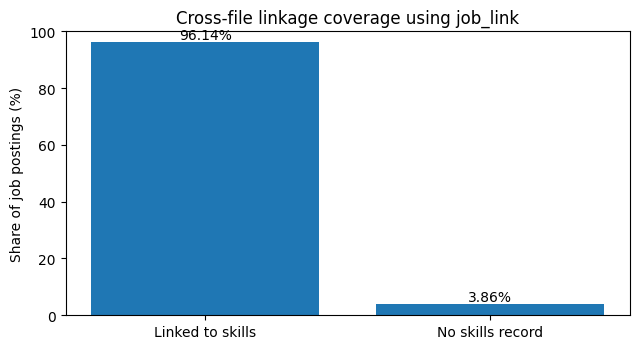

In [6]:
linked = float(linkage.loc[0, 'linkage_pct'])
unlinked = round(100-linked, 2)
plt.figure(figsize=(6.5,3.6))
plt.bar(['Linked to skills','No skills record'], [linked, unlinked])
plt.ylabel('Share of job postings (%)')
plt.title('Cross-file linkage coverage using job_link')
plt.ylim(0,100)
for i,v in enumerate([linked,unlinked]):
    plt.text(i, v+1, f'{v:.2f}%', ha='center')
plt.tight_layout()
plt.show()

## 6. Export evidence
The outputs below can be saved with the individual appendix as proof of work.

In [7]:
source_profile.to_csv('pratik_source_profile.csv', index=False)
linkage.to_csv('pratik_linkage_summary.csv', index=False)
analyst_summary.to_csv('pratik_analyst_ba_summary.csv', index=False)
integrated[integrated['job_title'].str.contains('analyst', case=False, na=False)].to_parquet(
    'pratik_integrated_analyst_subset.parquet', index=False
)
print('Evidence files exported.')

Evidence files exported.
